In [84]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [85]:
df = pd.read_csv(r"Funnel_Analysis_Data.csv")

In [86]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21409 entries, 0 to 21408
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User ID           21409 non-null  object 
 1   Session ID        21409 non-null  object 
 2   Event Time        21409 non-null  object 
 3   Event             21409 non-null  object 
 4   Device            21409 non-null  object 
 5   Region            21409 non-null  object 
 6   Channel           21409 non-null  object 
 7   Product Category  21409 non-null  object 
 8   Revenue           21409 non-null  float64
 9   Bonus Flag        21409 non-null  object 
dtypes: float64(1), object(9)
memory usage: 1.6+ MB


In [87]:
df['Event Time'] = pd.to_datetime(df['Event Time'])

In [88]:
#Checking Unique value of different columns 

categorical_cols = ['Event', 'Device', 'Region', 'Channel', 'Product Category']

for x in categorical_cols:
    print(f"\n{x}:")
    print(df[x].unique())


Event:
['Browse' 'Add to Cart' 'Checkout' 'Purchase']

Device:
['Tablet' 'Desktop' 'Mobile']

Region:
['South' 'East' 'West' 'North']

Channel:
['Organic' 'Email' 'Google Ads' 'Social Media']

Product Category:
['Electronics' 'Sports' 'Fashion' 'Beauty' 'Home']


In [89]:
# Calculating Conversion and Drop-Off Rates (Funnel Performance)

funnel = df.groupby('Event')['User ID'].nunique()
funnel

Event
Add to Cart     6949
Browse         10000
Checkout        3456
Purchase        1004
Name: User ID, dtype: int64

In [90]:
funnel = funnel.reindex([
    'Browse',
    'Add to Cart',
    'Checkout',
    'Purchase'
])

In [91]:
funnel 

Event
Browse         10000
Add to Cart     6949
Checkout        3456
Purchase        1004
Name: User ID, dtype: int64

In [92]:
conversion_rate = (funnel / funnel.shift(1)) * 100
conversion_rate = round(conversion_rate, 2)
conversion_rate

Event
Browse           NaN
Add to Cart    69.49
Checkout       49.73
Purchase       29.05
Name: User ID, dtype: float64

In [93]:
drop_off = 100 - conversion_rate
drop_off = round(drop_off, 2)

In [94]:
drop_off

Event
Browse           NaN
Add to Cart    30.51
Checkout       50.27
Purchase       70.95
Name: User ID, dtype: float64

In [95]:
overall_conversion = round((funnel['Purchase'] / funnel['Browse']) * 100, 2)
overall_drop_off = round(100 - overall_conversion, 2)
print(overall_conversion)
print(overall_drop_off)

10.04
89.96


In [96]:
# Customers Behaviour

session_events = df.groupby('Session ID')['Event'].agg(set)


In [97]:
abandoned_sessions = session_events[
    session_events.apply(
        lambda x: {'Browse', 'Add to Cart', 'Checkout'}.issubset(x)
        and 'Purchase' not in x
    )
]
print(len(abandoned_sessions))

2452


In [98]:
checkout_count = ( df['Event'] == 'Checkout').sum()
print(checkout_count)

3456


In [99]:
#Rate of people who abandoned the checkout process
abandone_rate = (len(abandoned_sessions) / checkout_count )*100 
print(round(abandone_rate, 2))

70.95


In [100]:
abandoned_data = df[df['Session ID'].isin(abandoned_sessions.index)]
abandoned_data.head()

,User ID,Session ID,Event Time,Event,Device,Region,Channel,Product Category,Revenue,Bonus Flag
0,USR-00001,SES-00001,2026-01-07 23:46:20.358501,Browse,Tablet,South,Organic,Electronics,0.0,Yes
1,USR-00001,SES-00001,2026-01-07 23:49:20.358501,Add to Cart,Tablet,South,Organic,Electronics,0.0,Yes
2,USR-00001,SES-00001,2026-01-07 23:51:20.358501,Checkout,Tablet,South,Organic,Electronics,0.0,Yes
6,USR-00004,SES-00004,2026-01-08 07:58:00.840696,Browse,Tablet,East,Organic,Sports,0.0,Yes
7,USR-00004,SES-00004,2026-01-08 08:00:00.840696,Add to Cart,Tablet,East,Organic,Sports,0.0,Yes


In [101]:
# Device in which abandon checkout process

abandoned_data.groupby('Device')['Session ID'].nunique()

Device
Desktop    826
Mobile     814
Tablet     812
Name: Session ID, dtype: int64

In [102]:
# Product category analysis (Purchase, Browsing)

Purchase_data = df[df['Event'] == 'Purchase'].copy()
purchase_groupby = Purchase_data.groupby('Product Category')['User ID'].nunique()

In [103]:
print(purchase_groupby.idxmax(), purchase_groupby.max())
print(purchase_groupby.idxmin(), purchase_groupby.min())


Electronics 229
Home 184


In [104]:
browse_data = df[df['Event'] == 'Browse'].copy()
browse_groupby = browse_data.groupby('Product Category')['User ID'].nunique()


In [105]:
print(browse_groupby.idxmax(), browse_groupby.max())
print(browse_groupby.idxmin(), browse_groupby.min())


Electronics 2052
Sports 1948


In [106]:
# Revenue By Region and Product Category

revenue_by_category = Purchase_data.groupby('Product Category')['Revenue'].sum()
print(revenue_by_category.idxmax(), revenue_by_category.max())
print(revenue_by_category.idxmin(), revenue_by_category.min())

Electronics 62938.46
Home 50100.01


In [107]:
revenue_by_region = Purchase_data.groupby('Region')['Revenue'].sum()
print(revenue_by_region.idxmax(), revenue_by_region.max())
print(revenue_by_region.idxmin(), revenue_by_region.min())


South 77421.45
West 65140.47


In [108]:
# Purchasers By Channel

purchase_channel = Purchase_data.groupby('Channel')['User ID'].nunique()
purchase_channel

Channel
Email           248
Google Ads      268
Organic         239
Social Media    249
Name: User ID, dtype: int64

In [109]:
# Time Analysis
Purchase_data['Hour'] = Purchase_data['Event Time'].dt.hour

In [110]:
# Hour of the day with most purchases
purchase_by_hour = Purchase_data.groupby('Hour')['User ID'].nunique()
print(purchase_by_hour.idxmax(), purchase_by_hour.max())
print(purchase_by_hour.idxmin(), purchase_by_hour.min())

12 53
0 33


In [111]:
Purchase_data['Day'] = Purchase_data['Event Time'].dt.day_name()

In [112]:
# Day of the week with most purchases
purchase_by_day = Purchase_data.groupby('Day')['User ID'].nunique()
print(purchase_by_day.idxmax(), purchase_by_day.max())
print(purchase_by_day.idxmin(), purchase_by_day.min())

Wednesday 178
Monday 120


In [113]:
browse_data['Hour'] = browse_data['Event Time'].dt.hour


In [114]:
# Hour of the day with most purchases
browse_by_hour = browse_data.groupby('Hour')['User ID'].nunique()
print(browse_by_hour.idxmax(), browse_by_hour.max())
print(browse_by_hour.idxmin(), browse_by_hour.min())

21 450
22 367


In [115]:
browse_data['Day'] = browse_data['Event Time'].dt.day_name()

In [116]:
#Day of the week with most purchases
browse_by_day = browse_data.groupby('Day')['User ID'].nunique()
print(browse_by_day.idxmax(), browse_by_day.max())
print(browse_by_day.idxmin(), browse_by_day.min())

Wednesday 1693
Monday 1307


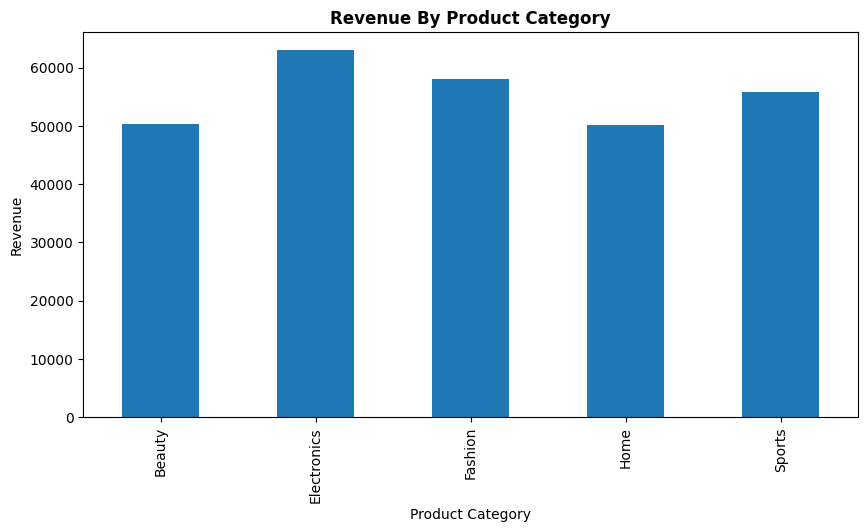

In [117]:
# CHARTS 

#Bar chart of Revenue by Category

revenue_by_category.plot(kind='bar', figsize=(10,5))

plt.title("Revenue By Product Category", fontweight='bold')
plt.xlabel('Product Category')
plt.ylabel('Revenue')
plt.show()

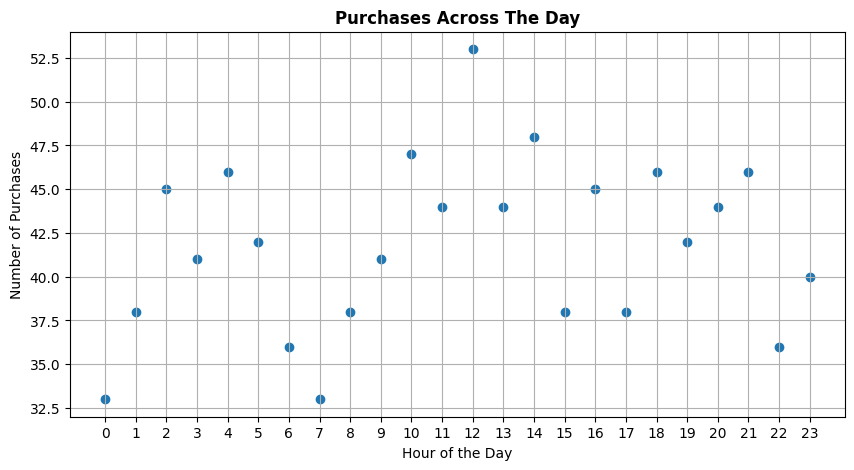

In [118]:
#Scatter chart of purchases across the day

plt.figure(figsize =(10,5))

plt.scatter(purchase_by_hour.index, purchase_by_hour.values)

plt.title('Purchases Across The Day', fontweight='bold')
plt.xlabel('Hour of the Day')
plt.ylabel('Number of Purchases')
plt.xticks(range(24))
plt.grid()
plt.show()